In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

In [3]:
print(movies.shape, ratings.shape)

(9742, 3) (100836, 4)


In [4]:
print(movies.columns, ratings.columns)

Index(['movieId', 'title', 'genres'], dtype='str') Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='str')


In [5]:
merged = pd.merge(ratings, movies, on="movieId")
merged.head(5)

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [6]:
print(ratings.shape, merged.shape)

(100836, 4) (100836, 6)


In [7]:
merged.isnull().sum()

userId       0
movieId      0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [8]:
movie_stats = merged.groupby("movieId")["rating"].agg(["mean", "count"])

In [9]:
movie_stats = movie_stats.reset_index()

In [10]:
movie_stats.head()

,movieId,mean,count
0,1,3.920930,215
1,2,3.431818,110
2,3,3.259615,52
3,4,2.357143,7
4,5,3.071429,49


In [11]:
movie_info = pd.merge(movie_stats, movies, on="movieId")
movie_info.head()

,movieId,mean,count,title,genres
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy


In [12]:
user1_liked = merged[(merged["userId"]==1) & (merged["rating"] >= 4.0)]
user1_liked.head()

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [13]:
genre_split = user1_liked["genres"].str.split("|")

In [14]:
user_genre = genre_split.explode()

In [15]:
genre_counts = user_genre.value_counts()
genre_counts.head()

genres
Action       76
Adventure    74
Comedy       70
Drama        64
Thriller     43
Name: count, dtype: int64

In [16]:
top_genres = genre_counts.head().index

print(top_genres)

Index(['Action', 'Adventure', 'Comedy', 'Drama', 'Thriller'], dtype='str', name='genres')


In [17]:
def has_preferred_genre(genres):
    genre_list = genres.split("|")
    return any(genre in top_genres for genre in genre_list)

candidates = movie_info[
    movie_info["genres"].apply(has_preferred_genre)
].copy()

candidates.head()

,movieId,mean,count,title,genres
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy


In [18]:
user1_rated = ratings[
    ratings["userId"] == 1
]["movieId"]

candidates = candidates[
    ~candidates["movieId"].isin(user1_rated)
].copy()

candidates.head()

,movieId,mean,count,title,genres
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy
6,7,3.185185,54,Sabrina (1995),Comedy|Romance
7,8,2.875000,8,Tom and Huck (1995),Adventure|Children


In [19]:
top10_mean = candidates.sort_values(
    by="mean",
    ascending=False
).head(10)

display(
    top10_mean[["title", "genres", "mean", "count"]]
)

,title,genres,mean,count
2317,"Sandpiper, The (1965)",Drama|Romance,5.0,1
48,Lamerica (1994),Adventure|Drama,5.0,2
5572,Sonatine (Sonachine) (1993),Action|Comedy|Crime|Drama,5.0,1
6194,Peaceful Warrior (2006),Drama,5.0,1
3918,Martin Lawrence Live: Runteldat (2002),Comedy|Documentary,5.0,1
9039,Oscar (1967),Comedy,5.0,1
9037,Bloodsucking Bastards (2015),Comedy|Horror,5.0,1
9028,12 Chairs (1976),Adventure|Comedy,5.0,1
5417,Mr. Skeffington (1944),Drama|Romance,5.0,1
3969,"Son of the Bride (Hijo de la novia, El) (2001)",Comedy|Drama,5.0,1


In [20]:
m = 100
C = ratings["rating"].mean()

v = candidates["count"]
R = candidates["mean"]

candidates["WR"] = (
    (v / (v + m)) * R
    + (m / (v + m)) * C
)

display(candidates[["title", "mean", "count", "WR"]].head())

,title,mean,count,WR
1,Jumanji (1995),3.431818,110,3.465027
3,Waiting to Exhale (1995),2.357143,7,3.426689
4,Father of the Bride Part II (1995),3.071429,49,3.360105
6,Sabrina (1995),3.185185,54,3.390621
7,Tom and Huck (1995),2.875000,8,3.455145


In [21]:
top10_wr = candidates.sort_values(
    by="WR",
    ascending=False
).head(10)

display(
    top10_wr[["title", "genres", "mean", "count", "WR"]]
)

,title,genres,mean,count,WR
277,"Shawshank Redemption, The (1994)",Crime|Drama,4.429022,317,4.206608
659,"Godfather, The (1972)",Crime|Drama,4.289062,192,4.019369
6693,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.238255,149,3.942392
921,"Godfather: Part II, The (1974)",Crime|Drama,4.259690,129,3.928628
3633,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.106061,198,3.903207
4791,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.118919,185,3.902301
895,One Flew Over the Cuckoo's Nest (1975),Drama,4.203008,133,3.901956
6298,"Departed, The (2006)",Crime|Drama|Thriller,4.252336,107,3.889641
3136,Memento (2000),Mystery|Thriller,4.122642,159,3.882841
602,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.268041,97,3.878963


In [22]:
print("평균 평점 기준 TOP 10")
display(top10_mean[["title", "mean", "count"]])

print("가중 평점 기준 TOP 10")
display(top10_wr[["title", "mean", "count", "WR"]])

평균 평점 기준 TOP 10


,title,mean,count
2317,"Sandpiper, The (1965)",5.0,1
48,Lamerica (1994),5.0,2
5572,Sonatine (Sonachine) (1993),5.0,1
6194,Peaceful Warrior (2006),5.0,1
3918,Martin Lawrence Live: Runteldat (2002),5.0,1
9039,Oscar (1967),5.0,1
9037,Bloodsucking Bastards (2015),5.0,1
9028,12 Chairs (1976),5.0,1
5417,Mr. Skeffington (1944),5.0,1
3969,"Son of the Bride (Hijo de la novia, El) (2001)",5.0,1


가중 평점 기준 TOP 10


,title,mean,count,WR
277,"Shawshank Redemption, The (1994)",4.429022,317,4.206608
659,"Godfather, The (1972)",4.289062,192,4.019369
6693,"Dark Knight, The (2008)",4.238255,149,3.942392
921,"Godfather: Part II, The (1974)",4.259690,129,3.928628
3633,"Lord of the Rings: The Fellowship of the Ring,...",4.106061,198,3.903207
4791,"Lord of the Rings: The Return of the King, The...",4.118919,185,3.902301
895,One Flew Over the Cuckoo's Nest (1975),4.203008,133,3.901956
6298,"Departed, The (2006)",4.252336,107,3.889641
3136,Memento (2000),4.122642,159,3.882841
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.268041,97,3.878963


In [23]:
mean_movie_ids = set(top10_mean["movieId"])
wr_movie_ids = set(top10_wr["movieId"])

common_movie_ids = mean_movie_ids & wr_movie_ids

print("공통 추천 영화 수:", len(common_movie_ids))

common_movies = movie_info[
    movie_info["movieId"].isin(common_movie_ids)
]

display(common_movies[["title", "mean", "count"]])

공통 추천 영화 수: 0


,title,mean,count


In [24]:
mean_rank = top10_mean[
    ["movieId", "title", "mean", "count"]
].copy()

mean_rank["mean_rank"] = range(1, len(mean_rank) + 1)

wr_rank = top10_wr[
    ["movieId", "WR"]
].copy()

wr_rank["wr_rank"] = range(1, len(wr_rank) + 1)

rank_comparison = pd.merge(
    mean_rank,
    wr_rank,
    on="movieId",
    how="outer"
)

display(rank_comparison)

,movieId,title,mean,count,mean_rank,WR,wr_rank
0,53,Lamerica (1994),5.0,2.0,2.0,NaN,NaN
1,318,NaN,NaN,NaN,NaN,4.206608,1.0
2,750,NaN,NaN,NaN,NaN,3.878963,10.0
3,858,NaN,NaN,NaN,NaN,4.019369,2.0
4,1193,NaN,NaN,NaN,NaN,3.901956,7.0
5,1221,NaN,NaN,NaN,NaN,3.928628,4.0
6,3073,"Sandpiper, The (1965)",5.0,1.0,1.0,NaN,NaN
7,4226,NaN,NaN,NaN,NaN,3.882841,9.0
8,4993,NaN,NaN,NaN,NaN,3.903207,5.0
9,5513,Martin Lawrence Live: Runteldat (2002),5.0,1.0,5.0,NaN,NaN


In [25]:
print("추천 후보 영화 수:", len(candidates))

print("평균 평점 통계")
display(candidates["mean"].describe())

print("평가 수 통계")
display(candidates["count"].describe())

print("가중 평점 통계")
display(candidates["WR"].describe())

추천 후보 영화 수: 8524
평균 평점 통계


count    8524.000000
mean        3.243050
std         0.857071
min         0.500000
25%         2.750000
50%         3.375000
75%         3.863636
max         5.000000
Name: mean, dtype: float64

평가 수 통계


count    8524.000000
mean        9.494486
std        18.631689
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       317.000000
Name: count, dtype: float64

가중 평점 통계


count    8524.000000
mean        3.494491
std         0.057394
min         3.053305
25%         3.477673
50%         3.496624
75%         3.511220
max         4.206608
Name: WR, dtype: float64

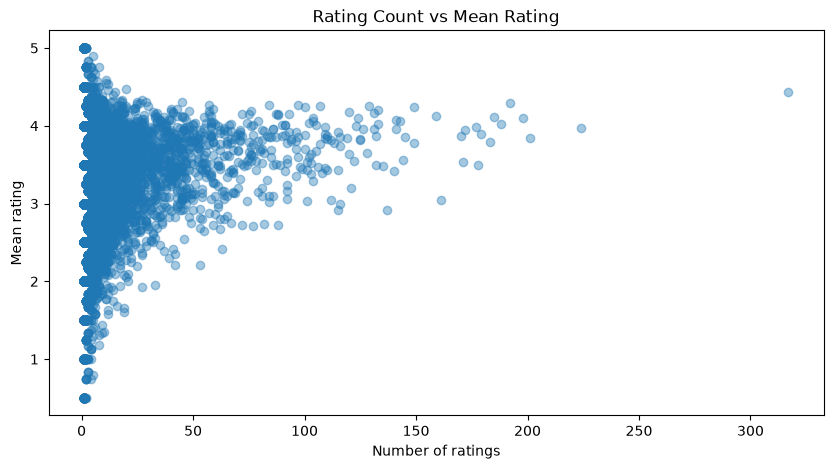

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    candidates["count"],
    candidates["mean"],
    alpha=0.4
)

plt.xlabel("Number of ratings")
plt.ylabel("Mean rating")
plt.title("Rating Count vs Mean Rating")

plt.show()

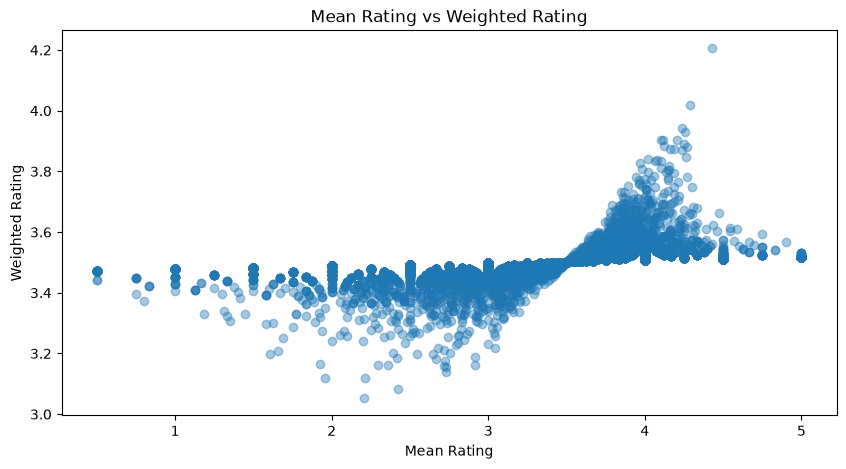

In [27]:
plt.figure(figsize=(10, 5))

plt.scatter(
    candidates["mean"],
    candidates["WR"],
    alpha=0.4
)

plt.xlabel("Mean Rating")
plt.ylabel("Weighted Rating")
plt.title("Mean Rating vs Weighted Rating")

plt.show()

In [ ]:
def recommend_movies(user_id, top_n=10, m=100):

    user_ratings = merged[
        merged["userId"] == user_id
    ]

    if user_ratings.empty:
        print("평가 기록이 없는 사용자입니다.")
        return pd.DataFrame()

    liked_movies = user_ratings[
        user_ratings["rating"] >= 4.0
    ]

    if liked_movies.empty:
        print("선호 장르를 추출할 수 없습니다.")
        return pd.DataFrame()

    genre_counts = (
        liked_movies["genres"]
        .str.split("|")
        .explode()
        .value_counts()
    )

    preferred_genres = genre_counts.head(5).index

    def has_preferred_genre(genres):
        genre_list = genres.split("|")
        return any(
            genre in preferred_genres
            for genre in genre_list
        )

    user_candidates = movie_info[
        movie_info["genres"].apply(has_preferred_genre)
    ].copy()

    rated_movie_ids = user_ratings["movieId"]

    user_candidates = user_candidates[
        ~user_candidates["movieId"].isin(rated_movie_ids)
    ].copy()

    C = ratings["rating"].mean()

    v = user_candidates["count"]
    R = user_candidates["mean"]

    user_candidates["WR"] = (
        (v / (v + m)) * R
        + (m / (v + m)) * C
    )

    recommendations = user_candidates.sort_values(
        by="WR",
        ascending=False
    ).head(top_n)

    return recommendations[
        ["movieId", "title", "genres", "mean", "count", "WR"]
    ]

In [30]:
recommendations_user1 = recommend_movies(
    user_id=1,
    top_n=10
)

display(recommendations_user1)

,movieId,title,genres,mean,count,WR
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429022,317,4.206608
659,858,"Godfather, The (1972)",Crime|Drama,4.289062,192,4.019369
6693,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.238255,149,3.942392
921,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.259690,129,3.928628
3633,4993,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.106061,198,3.903207
4791,7153,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.118919,185,3.902301
895,1193,One Flew Over the Cuckoo's Nest (1975),Drama,4.203008,133,3.901956
6298,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.252336,107,3.889641
3136,4226,Memento (2000),Mystery|Thriller,4.122642,159,3.882841
602,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.268041,97,3.878963


In [31]:
recommendations_user2 = recommend_movies(
    user_id=2,
    top_n=10
)

display(recommendations_user2)

,movieId,title,genres,mean,count,WR
2224,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.272936,218,4.030364
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197068,307,4.026181
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231076,251,4.023236
659,858,"Godfather, The (1972)",Crime|Drama,4.289062,192,4.019369
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164134,329,4.009687
1938,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192446,278,4.009671
461,527,Schindler's List (1993),Drama|War,4.225000,220,3.998924
46,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.237745,204,3.995578
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.161290,279,3.987218
897,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,4.215640,211,3.986031


In [32]:
user1_ids = set(recommendations_user1["movieId"])
user2_ids = set(recommendations_user2["movieId"])

common_recommendations = user1_ids & user2_ids

print(
    "사용자 1과 사용자 2의 공통 추천 영화 수:",
    len(common_recommendations)
)

사용자 1과 사용자 2의 공통 추천 영화 수: 1


In [33]:
user1_rated_ids = set(
    ratings[ratings["userId"] == 1]["movieId"]
)

recommended_ids = set(
    recommendations_user1["movieId"]
)

already_rated = recommended_ids & user1_rated_ids

print("이미 평가한 영화가 추천된 수:", len(already_rated))

이미 평가한 영화가 추천된 수: 0


In [34]:
for _, movie in recommendations_user1.iterrows():

    movie_genres = movie["genres"].split("|")

    matched_genres = [
        genre
        for genre in movie_genres
        if genre in top_genres
    ]

    print(movie["title"], ":", matched_genres)

Shawshank Redemption, The (1994) : ['Drama']
Godfather, The (1972) : ['Drama']
Dark Knight, The (2008) : ['Action', 'Drama']
Godfather: Part II, The (1974) : ['Drama']
Lord of the Rings: The Fellowship of the Ring, The (2001) : ['Adventure']
Lord of the Rings: The Return of the King, The (2003) : ['Action', 'Adventure', 'Drama']
One Flew Over the Cuckoo's Nest (1975) : ['Drama']
Departed, The (2006) : ['Drama', 'Thriller']
Memento (2000) : ['Thriller']
Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964) : ['Comedy']


In [35]:
recommendations_user1.to_csv(
    "recommendations_user1.csv",
    index=False,
    encoding="utf-8-sig"
)

print("추천 결과 저장 완료")

추천 결과 저장 완료
